# Analysis — all arms

Statistical analysis from proposal Bab III (3.6 Metrik Evaluasi, 3.7 Analisis Statistik), on the results in the private
dataset repo `dimsmauls/code4ml-eval-outputs`.

| RQ | Data | Method |
|---|---|---|
| RQ1, RQ3 structural | `<run>/code4ml_ratings.csv` (SonarQube + MLScent on the 304 Code4ML test answers) | Friedman (vanilla, few-shot, LoRA, QLoRA) → Wilcoxon signed-rank + Holm (5 comparisons); Kendall's W, rank-biserial r; 14B family (3 comparisons, own Holm); sensitivity on density per 100 `ncloc` |
| RQ3, RQ4 functional | `<run>/ds1000_results.jsonl` (DS-1000, 997 problems × 10 samples) | Cochran's Q → McNemar + Holm; paired bootstrap 95% CI of the difference in proportions |
| RQ2 | both | Arm-level comparison of structural quality and functional correctness |
| RQ4 | `refinement-<method>/seed-*/refinement_results.jsonl` | Cochran's Q over iterations → McNemar between consecutive iterations + Holm; bootstrap CI; saturation point |

Rules from the proposal: unit = the same prompt / problem in every arm; for LoRA and QLoRA the value per prompt is the
median of the 3 seeds (seed variation reported descriptively); only AST-valid code is rated; paired tests use complete
blocks only; alpha = 0.05.

**Colab:** add a Hugging Face token with read access as the secret `HF_TOKEN` (key icon on the left), then Run all.
`code4ml_ratings.csv` comes from `rating/rate_outputs.ipynb`; run that first.

## 1. Setup

In [1]:
%pip install -q pandas scipy statsmodels huggingface_hub matplotlib   # into the selected kernel (Colab or local)



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os

try:  # Colab secret; elsewhere an existing `hf auth login` is used
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass

import json
from collections import Counter

import numpy as np
import pandas as pd
from huggingface_hub import HfApi, hf_hub_download
from scipy import stats
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

REPO = "dimsmauls/code4ml-eval-outputs"
SEEDS = (42, 43, 44)
RUNS = {"vanilla": ["vanilla"], "few-shot": ["few-shot"], "qwen-14b": ["qwen-14b"],
        "lora": [f"lora/seed-{s}" for s in SEEDS], "qlora": [f"qlora/seed-{s}" for s in SEEDS]}
FRIEDMAN_ARMS = ["vanilla", "few-shot", "lora", "qlora"]
MAIN_FAMILY = [("lora", "vanilla"), ("qlora", "vanilla"), ("lora", "few-shot"), ("qlora", "few-shot"), ("lora", "qlora")]
FAMILY_14B = [("qwen-14b", "lora"), ("qwen-14b", "qlora"), ("qwen-14b", "vanilla")]
ALPHA = 0.05
BOOTSTRAP = 10_000
SEED = 42

files = set(HfApi().list_repo_files(REPO, repo_type="dataset"))
missing = [f"{run}/{name}" for runs in RUNS.values() for run in runs
           for name in ("code4ml_ratings.csv", "ds1000_results.jsonl", "summary.json") if f"{run}/{name}" not in files]
print("missing on the Hub:", missing or "nothing")


def get(path):
    return hf_hub_download(REPO, path, repo_type="dataset")

/Users/dimasmaulana/.venvs/mlx/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


missing on the Hub: nothing


## 2. Shared tests

- `friedman`: omnibus over k paired conditions; Kendall's W = χ² / (n (k − 1)).
- `wilcoxon_family`: Wilcoxon signed-rank per pair (zero differences dropped), Holm within the family; rank-biserial
  r = (R⁺ − R⁻) / (R⁺ + R⁻). Difference = first − second, so for ratings and counts a **negative** difference means the
  first arm is better.
- `mcnemar_family`: exact McNemar per pair, Holm within the family; difference in proportions with a paired bootstrap
  95% CI over problems.

In [3]:
def holm(pvalues):
    return multipletests(pvalues, method="holm")[1]


def bootstrap_ci(diffs):
    """Paired bootstrap over units: 95% CI of the mean of per-unit differences."""
    diffs = np.asarray(diffs, dtype=float)
    rng = np.random.default_rng(SEED)
    means = diffs[rng.integers(0, len(diffs), (BOOTSTRAP, len(diffs)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def friedman(table, arms):
    block = table[arms].dropna()
    chi2, p = stats.friedmanchisquare(*(block[a] for a in arms))
    return {"n": len(block), "chi2": chi2, "p": p, "kendall_w": chi2 / (len(block) * (len(arms) - 1))}


def wilcoxon_family(table, pairs):
    rows = []
    for a, b in pairs:
        diff = (table[a] - table[b]).dropna()
        nonzero = diff[diff != 0]
        if len(nonzero):
            p = stats.wilcoxon(nonzero).pvalue
            ranks = stats.rankdata(nonzero.abs())
            r = (ranks[nonzero.to_numpy() > 0].sum() - ranks[nonzero.to_numpy() < 0].sum()) / ranks.sum()
        else:
            p, r = 1.0, 0.0
        rows.append({"comparison": f"{a} − {b}", "n": len(diff), "median_diff": diff.median(),
                     "mean_diff": diff.mean(), "p": p, "rank_biserial": r})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p"])
    out["significant"] = out["p_holm"] < ALPHA
    return out


def mcnemar_family(table, pairs):
    rows = []
    for a, b in pairs:
        block = table[[a, b]].dropna().astype(int)
        both, only_a = ((block[a] == 1) & (block[b] == 1)).sum(), ((block[a] == 1) & (block[b] == 0)).sum()
        only_b, neither = ((block[a] == 0) & (block[b] == 1)).sum(), ((block[a] == 0) & (block[b] == 0)).sum()
        p = mcnemar([[both, only_a], [only_b, neither]], exact=True).pvalue
        low, high = bootstrap_ci(block[a] - block[b])
        rows.append({"comparison": f"{a} − {b}", "n": len(block), "rate_a": block[a].mean(), "rate_b": block[b].mean(), "diff": block[a].mean() - block[b].mean(),
                     "ci95_low": low, "ci95_high": high, "a_only": only_a, "b_only": only_b, "p": p})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p"])
    out["significant"] = out["p_holm"] < ALPHA
    return out


def per_arm(frames_by_run, how):
    """One value per unit and arm. LoRA/QLoRA: median of the 3 seeds; only units present in all 3 seeds."""
    out = {}
    for arm, runs in RUNS.items():
        frames = [frames_by_run[run] for run in runs]
        if len(frames) == 1:
            out[arm] = frames[0]
            continue
        stacked = pd.concat(frames, keys=range(len(frames)))
        median = stacked.groupby(level=1).median()
        complete = stacked.groupby(level=1).count() == len(frames)
        out[arm] = how(median.where(complete))
    return out

### Chart style

In [4]:
import matplotlib.pyplot as plt

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
GRADE_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # one-hue ordinal ramp, A (light) -> E (dark)
NA_COLOR = "#b5b4af"                                                       # neutral gray: not rated (N/A)
BAR, LINE = "#2a78d6", {"lora": "#2a78d6", "qlora": "#eb6834"}            # categorical slots 1-2
ARM_ORDER = ["vanilla", "few-shot", "lora", "qlora", "qwen-14b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 120, "pdf.fonttype": 42,   # TrueType fonts in PDFs
})


def pooled(arm):
    """All answers of an arm (the 3 seeds pooled for LoRA / QLoRA); descriptive charts only."""
    return pd.concat([ratings[run] for run in RUNS[arm]])

## 3. Structural quality (RQ1, RQ3)

Ratings are ordinal 1 = A (best) … 5 = E. SonarQube metrics are missing when SonarQube could not analyse the code
(no `ncloc`); MLScent rating is missing when MLScent returned N/A. Only AST-valid code is rated.


**Unit:** the 304 test rows share 40 unique instructions and answers are greedy, so the tables and tests below use
one value per unique instruction (median of its duplicate rows); the AST validity rate and the distribution charts stay
per answer.

In [5]:
GRADE = {g: i for i, g in enumerate("ABCDE", 1)}
PRIMARY = ["maintainability", "code_smells", "complexity", "cognitive_complexity", "bugs"]
SECONDARY = ["mlscent_ml_rating"]
DENSITY = ["code_smells_per_100_ncloc", "ml_findings_per_100_ncloc"]


def load_ratings(run):
    df = pd.read_csv(get(f"{run}/code4ml_ratings.csv"), dtype={"id": str})
    valid = df["ast_valid"].astype(str) == "True"
    ncloc = pd.to_numeric(df["ncloc"], errors="coerce")
    sonar = valid & (ncloc > 0)                       # SonarQube N/A without ncloc
    out = pd.DataFrame(index=df["id"])
    out["ast_valid"] = valid.to_numpy()
    out["ncloc"] = ncloc.where(sonar).to_numpy()
    out["maintainability"] = df["maintainability_rating"].map(GRADE).where(sonar).to_numpy()
    for metric in ("code_smells", "complexity", "cognitive_complexity", "bugs"):
        out[metric] = pd.to_numeric(df[metric], errors="coerce").where(sonar).to_numpy()
    out["mlscent_ml_rating"] = df["mlscent_ml_rating"].map(GRADE).where(valid).to_numpy()   # 'N/A' -> missing
    ml_findings = df["mlscent_ml_findings_json"].map(lambda s: len(json.loads(s)) if isinstance(s, str) and s else np.nan)
    out["code_smells_per_100_ncloc"] = 100 * out["code_smells"] / out["ncloc"]
    out["ml_findings_per_100_ncloc"] = (100 * ml_findings.to_numpy() / out["ncloc"]).where(out["mlscent_ml_rating"].notna())
    return out


ratings = {run: load_ratings(run) for runs in RUNS.values() for run in runs}
# Unit of the structural tests = unique test instruction. The 304 test rows share 40 instruction texts (one
# template per subclass) and Code4ML answers are greedy, so duplicate rows are collapsed to their median per run.
INSTRUCTION_OF = pd.read_csv(get("vanilla/code4ml_ratings.csv"), dtype={"id": str}).set_index("id")["graph_vertex_subclass"]


def by_instruction(df):
    return df.drop(columns="ast_valid").groupby(INSTRUCTION_OF.reindex(df.index).to_numpy()).median()


arm_ratings = per_arm({run: by_instruction(df) for run, df in ratings.items()}, lambda df: df)
METRICS = PRIMARY + SECONDARY + DENSITY
tables = {m: pd.DataFrame({arm: df[m] for arm, df in arm_ratings.items()}) for m in METRICS + ["ncloc"]}

### 3.1 Descriptive: AST validity gate, code length, metrics per arm

In [6]:
def describe(df, runs):
    return {"ast_valid_rate": np.mean([ratings[r]["ast_valid"].mean() for r in runs]),
            "sonar_rated": int(df["maintainability"].notna().sum()),
            "mlscent_rated": int(df["mlscent_ml_rating"].notna().sum()),
            "median_ncloc": df["ncloc"].median(),
            "maintainability_A_%": 100 * (df["maintainability"] == 1).sum() / df["maintainability"].notna().sum(),
            **{f"mean_{m}": df[m].mean() for m in METRICS}}


# One row per arm (LoRA / QLoRA = median of the 3 seeds per prompt), then one row per seed (descriptive only)
descriptive = pd.DataFrame({arm: describe(arm_ratings[arm], runs) for arm, runs in RUNS.items()}).T
per_seed = pd.DataFrame({run: describe(by_instruction(ratings[run]), [run]) for arm in ("lora", "qlora") for run in RUNS[arm]}).T
pd.concat([descriptive, per_seed]).round(3)

,ast_valid_rate,sonar_rated,mlscent_rated,median_ncloc,maintainability_A_%,mean_maintainability,mean_code_smells,mean_complexity,mean_cognitive_complexity,mean_bugs,mean_mlscent_ml_rating,mean_code_smells_per_100_ncloc,mean_ml_findings_per_100_ncloc
vanilla,0.980,39.0,34.0,13.0,100.000,1.000,0.256,0.205,0.205,0.000,1.588,2.075,5.116
few-shot,1.000,40.0,8.0,2.0,97.500,1.025,0.050,0.025,0.025,0.000,2.250,1.458,27.292
qwen-14b,1.000,40.0,34.0,13.0,100.000,1.000,0.225,0.375,0.375,0.000,1.618,1.693,5.569
lora,0.974,39.0,5.0,2.0,97.436,1.026,0.154,0.000,0.000,0.000,1.200,3.022,2.857
qlora,0.977,39.0,5.0,2.0,97.436,1.026,0.154,0.026,0.026,0.000,1.000,3.083,0.000
lora/seed-42,0.990,40.0,10.0,2.0,97.500,1.025,0.075,0.025,0.000,0.000,1.200,1.964,10.714
lora/seed-43,0.931,39.0,7.0,2.0,94.872,1.051,0.205,0.051,0.051,0.026,1.429,4.589,11.791
lora/seed-44,1.000,40.0,6.0,2.0,100.000,1.000,0.150,0.150,0.150,0.025,1.333,1.679,10.714
qlora/seed-42,1.000,40.0,9.0,2.5,95.000,1.050,0.100,0.100,0.075,0.025,1.222,2.607,10.476
qlora/seed-43,0.931,39.0,7.0,2.0,94.872,1.051,0.154,0.000,0.000,0.000,1.143,3.938,8.163


#### Figures: rating distributions and code length (AST-valid answers, seeds pooled)

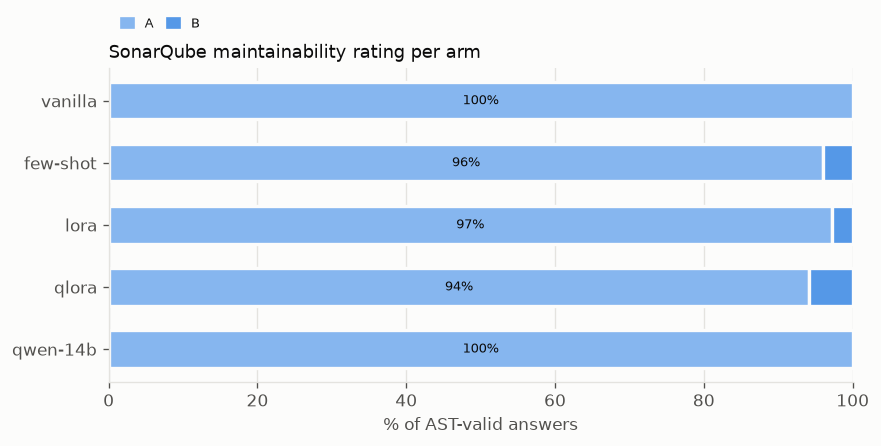

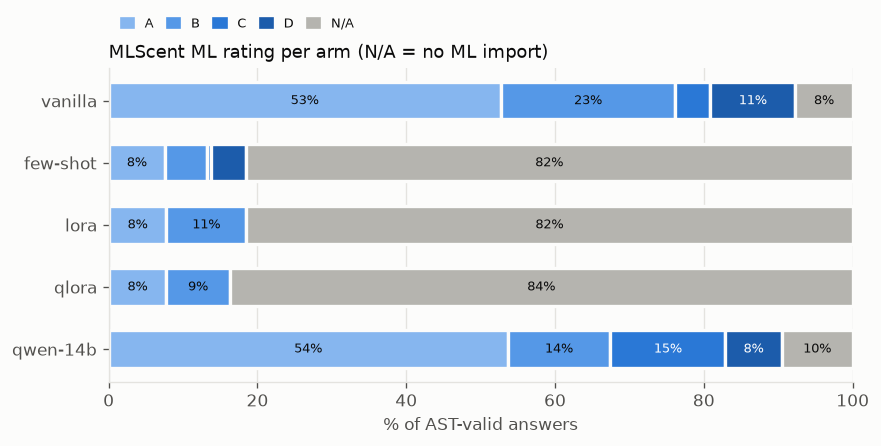

In [7]:
def grade_shares(column):
    """% of AST-valid answers per grade A-E, plus % not rated (N/A)."""
    rows = {}
    for arm in ARM_ORDER:
        values = pooled(arm).loc[lambda df: df["ast_valid"], column]
        rows[arm] = [100 * (values == g).mean() for g in range(1, 6)] + [100 * values.isna().mean()]
    return pd.DataFrame(rows, index=list("ABCDE") + ["N/A"]).T


def stacked_bars(shares, title):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    colors = GRADE_COLORS + [NA_COLOR]
    for y, arm in enumerate(shares.index):
        left = 0.0
        for (label, value), color in zip(shares.loc[arm].items(), colors):
            if value <= 0:
                continue
            ax.barh(y, value, left=left, height=0.6, color=color, edgecolor=SURFACE, linewidth=2)
            if value >= 7:
                dark = color in GRADE_COLORS[2:]
                ax.text(left + value / 2, y, f"{value:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if dark else INK)
            left += value
    ax.set_yticks(range(len(shares)), shares.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of AST-valid answers")
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=11)
    present = [(label, color) for label, color in zip(shares.columns, colors) if shares[label].sum() > 0]
    handles = [plt.Rectangle((0, 0), 1, 1, color=color) for _, color in present]
    ax.legend(handles, [label for label, _ in present], ncol=6, frameon=False, loc="lower left",
              bbox_to_anchor=(0, 1.08), fontsize=8, handlelength=1, columnspacing=1)
    plt.show()


stacked_bars(grade_shares("maintainability"), "SonarQube maintainability rating per arm")
stacked_bars(grade_shares("mlscent_ml_rating"), "MLScent ML rating per arm (N/A = no ML import)")

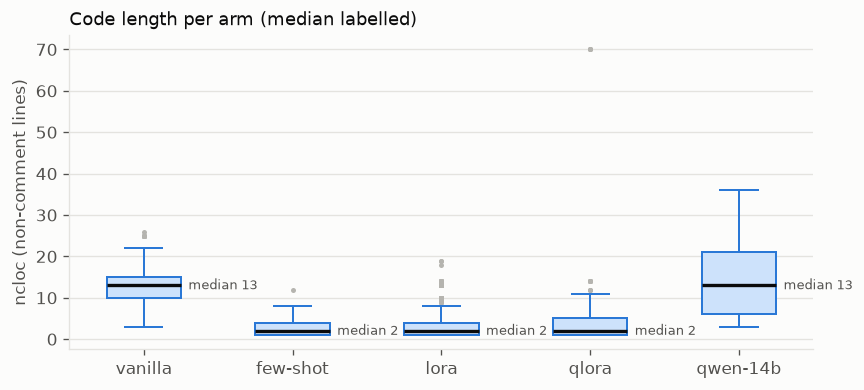

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
data = [pooled(arm)["ncloc"].dropna() for arm in ARM_ORDER]
ax.boxplot(data, tick_labels=ARM_ORDER, widths=0.5, patch_artist=True, showfliers=True,
           boxprops={"facecolor": "#cde2fb", "edgecolor": BAR, "linewidth": 1.2},
           whiskerprops={"color": BAR, "linewidth": 1.2}, capprops={"color": BAR, "linewidth": 1.2},
           medianprops={"color": INK, "linewidth": 2},
           flierprops={"marker": "o", "markersize": 3, "markerfacecolor": NA_COLOR, "markeredgecolor": "none"})
for x, values in enumerate(data, 1):
    ax.text(x + 0.3, values.median(), f"median {values.median():.0f}", va="center", ha="left", fontsize=8, color=INK_2)
ax.set_ylabel("ncloc (non-comment lines)")
ax.grid(axis="x", visible=False)
ax.set_title("Code length per arm (median labelled)", loc="left", fontsize=11)
plt.show()

### 3.2 Friedman (vanilla, few-shot, LoRA, QLoRA) → Wilcoxon + Holm (5 comparisons)

Post-hoc only when the omnibus test is significant. Primary = SonarQube metrics, secondary = MLScent rating.

In [9]:
def structural_tests(metrics):
    for metric in metrics:
        omnibus = friedman(tables[metric], FRIEDMAN_ARMS)
        print(f"\n=== {metric} | Friedman n={omnibus['n']} chi2={omnibus['chi2']:.3f} p={omnibus['p']:.4g} "
              f"Kendall's W={omnibus['kendall_w']:.3f}")
        if omnibus["p"] < ALPHA:
            display(wilcoxon_family(tables[metric], MAIN_FAMILY).round(4))
        else:
            print("not significant: no post-hoc")


structural_tests(PRIMARY + SECONDARY)


=== maintainability | Friedman n=38 chi2=3.000 p=0.3916 Kendall's W=0.026
not significant: no post-hoc

=== code_smells | Friedman n=38 chi2=5.684 p=0.128 Kendall's W=0.050
not significant: no post-hoc

=== complexity | Friedman n=38 chi2=11.333 p=0.01005 Kendall's W=0.099


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,38,0.0,-0.2105,0.0625,-1.0000,0.3125,False
1,qlora − vanilla,38,0.0,-0.1842,0.1562,-0.7619,0.6250,False
2,lora − few-shot,39,0.0,-0.0256,1.0000,-1.0000,1.0000,False
3,qlora − few-shot,39,0.0,0.0000,1.0000,0.0000,1.0000,False
4,lora − qlora,39,0.0,-0.0256,1.0000,-1.0000,1.0000,False



=== cognitive_complexity | Friedman n=38 chi2=8.600 p=0.03511 Kendall's W=0.075


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,lora − vanilla,38,0.0,-0.2105,0.1250,-1.0000,0.625,False
1,qlora − vanilla,38,0.0,-0.1842,0.3125,-0.6667,1.000,False
2,lora − few-shot,39,0.0,-0.0256,1.0000,-1.0000,1.000,False
3,qlora − few-shot,39,0.0,0.0000,1.0000,0.0000,1.000,False
4,lora − qlora,39,0.0,-0.0256,1.0000,-1.0000,1.000,False



=== bugs | Friedman n=38 chi2=nan p=nan Kendall's W=nan
not significant: no post-hoc

=== mlscent_ml_rating | Friedman n=3 chi2=5.824 p=0.1205 Kendall's W=0.647
not significant: no post-hoc


/Users/dimasmaulana/.venvs/mlx/lib/python3.14/site-packages/scipy/stats/_stats_py.py:8776: RuntimeWarning: invalid value encountered in scalar divide
  statistic = (12.0 / (k*count*(k+1)) * ssbn - 3*count*(k+1)) / c


### 3.3 Sensitivity: the same tests on density per 100 `ncloc`

In [10]:
structural_tests(DENSITY)


=== code_smells_per_100_ncloc | Friedman n=38 chi2=3.940 p=0.268 Kendall's W=0.035
not significant: no post-hoc

=== ml_findings_per_100_ncloc | Friedman n=3 chi2=4.895 p=0.1797 Kendall's W=0.544
not significant: no post-hoc


### 3.4 Qwen2.5-Coder-14B family (14B vs LoRA, QLoRA, vanilla 7B; own Holm correction)

In [11]:
for metric in PRIMARY + SECONDARY + DENSITY:
    print(f"\n=== {metric}")
    display(wilcoxon_family(tables[metric], FAMILY_14B).round(4))


=== maintainability


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,39,0.0,-0.0256,1.0,-1.0,1.0,False
1,qwen-14b − qlora,39,0.0,-0.0256,1.0,-1.0,1.0,False
2,qwen-14b − vanilla,39,0.0,0.0000,1.0,0.0,1.0,False



=== code_smells


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,39,0.0,0.0769,0.6401,0.1978,1.0,False
1,qwen-14b − qlora,39,0.0,0.0769,0.6279,0.2273,1.0,False
2,qwen-14b − vanilla,39,0.0,-0.0256,1.0000,-0.1429,1.0,False



=== complexity


...

,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,5,1.0,0.8000,0.3750,0.7000,0.7500,False
1,qwen-14b − qlora,5,1.0,1.0000,0.2500,1.0000,0.7500,False
2,qwen-14b − vanilla,34,0.0,0.0294,0.9385,0.0606,0.9385,False



=== code_smells_per_100_ncloc


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,39,0.0,-1.2857,0.6731,-0.1429,1.0,False
1,qwen-14b − qlora,39,0.0,-1.3467,0.5571,-0.2051,1.0,False
2,qwen-14b − vanilla,39,0.0,-0.3382,0.6523,-0.2000,1.0,False



=== ml_findings_per_100_ncloc


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
0,qwen-14b − lora,5,9.0909,4.0300,0.6250,0.4000,1.00,False
1,qwen-14b − qlora,5,9.0909,6.8871,0.2500,1.0000,0.75,False
2,qwen-14b − vanilla,34,0.0000,0.4531,0.8971,0.0368,1.00,False


## 4. Functional correctness (RQ3, RQ4 baseline)

Binary result per problem: **Pass@1 = the first sample (sample 0) passes; Pass@10 = at least one of the 10 samples
passes.** LoRA/QLoRA: median (majority) of the 3 seeds. The unbiased pass@k estimates from `summary.json` are reported
descriptively.

In [12]:
def ds1000_binary(run):
    res = pd.read_json(get(f"{run}/ds1000_results.jsonl"), lines=True)
    first = res[res["sample"] == 0].set_index("problem_id")["passed"].astype(float)
    any_pass = res.groupby("problem_id")["passed"].any().astype(float)
    return pd.DataFrame({"pass1": first, "pass10": any_pass})


binary = {run: ds1000_binary(run) for runs in RUNS.values() for run in runs}
arm_binary = per_arm(binary, lambda df: df.round())          # median of three 0/1 values = majority
pass_tables = {k: pd.DataFrame({arm: df[k] for arm, df in arm_binary.items()}) for k in ("pass1", "pass10")}

summaries = {run: json.load(open(get(f"{run}/summary.json"))) for runs in RUNS.values() for run in runs}
functional = pd.DataFrame([{"arm": arm,
                            "pass@1 (unbiased, mean of seeds)": np.mean([summaries[r]["ds1000"]["pass@1"] for r in runs]),
                            "pass@10 (unbiased, mean of seeds)": np.mean([summaries[r]["ds1000"]["pass@10"] for r in runs]),
                            "pass1 binary rate": pass_tables["pass1"][arm].mean(),
                            "pass10 binary rate": pass_tables["pass10"][arm].mean()} for arm, runs in RUNS.items()])
functional.set_index("arm").round(4)

,"pass@1 (unbiased, mean of seeds)","pass@10 (unbiased, mean of seeds)",pass1 binary rate,pass10 binary rate
arm,,,,
vanilla,0.3634,0.6620,0.3721,0.6620
few-shot,0.4470,0.6680,0.4393,0.6680
qwen-14b,0.2757,0.5416,0.2798,0.5416
lora,0.3143,0.6138,0.3089,0.6128
qlora,0.3159,0.6185,0.3039,0.6118


In [13]:
# Seed variation (descriptive only)
pd.DataFrame([{"run": run, "pass@1": summaries[run]["ds1000"]["pass@1"], "pass@10": summaries[run]["ds1000"]["pass@10"]}
              for arm in ("lora", "qlora") for run in RUNS[arm]]).set_index("run").round(4)

,pass@1,pass@10
run,,
lora/seed-42,0.3168,0.6179
lora/seed-43,0.3086,0.6058
lora/seed-44,0.3175,0.6179
qlora/seed-42,0.3158,0.6229
qlora/seed-43,0.3152,0.6138
qlora/seed-44,0.3166,0.6189


#### Figure: Pass@1 and Pass@10 per arm

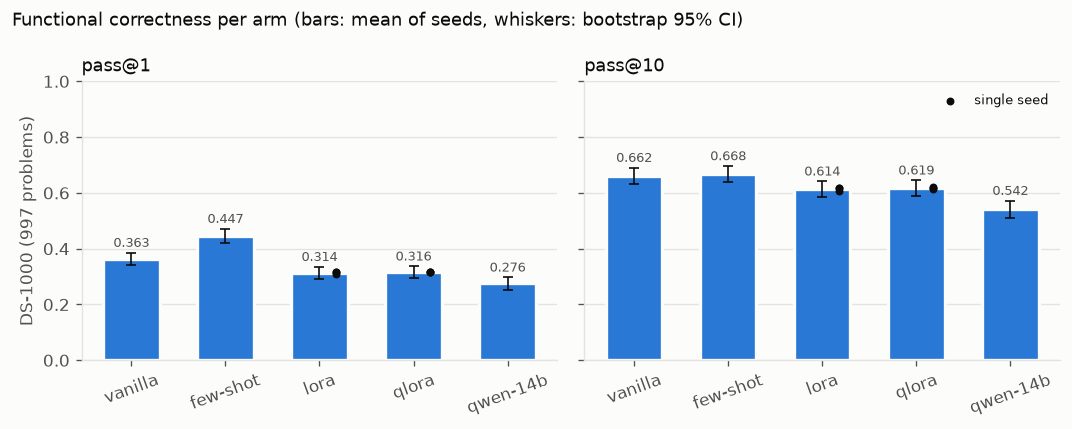

In [14]:
per_problem = {run: pd.DataFrame(json.load(open(get(f"{run}/ds1000_per_problem.json")))).T.astype(float)
               for runs in RUNS.values() for run in runs}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, k in zip(axes, ("pass@1", "pass@10")):
    for x, arm in enumerate(ARM_ORDER):
        runs = RUNS[arm]
        per_arm_problem = pd.concat([per_problem[r][k] for r in runs], axis=1).mean(axis=1)   # mean of seeds
        value = per_arm_problem.mean()
        low, high = bootstrap_ci(per_arm_problem)
        ax.bar(x, value, width=0.6, color=BAR, edgecolor=SURFACE, linewidth=2)
        ax.errorbar(x, value, yerr=[[value - low], [high - value]], color=INK, capsize=3, linewidth=1)
        if len(runs) > 1:
            seeds = [summaries[r]["ds1000"][k] for r in runs]
            ax.scatter([x + 0.18] * len(seeds), seeds, s=14, color=INK, zorder=3, label="single seed" if x == 2 else None)
        ax.text(x, high + 0.02, f"{value:.3f}", ha="center", fontsize=8, color=INK_2)
    ax.set_xticks(range(len(ARM_ORDER)), ARM_ORDER, rotation=20)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.set_title(k, loc="left", fontsize=11)
axes[0].set_ylabel("DS-1000 (997 problems)")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Functional correctness per arm (bars: mean of seeds, whiskers: bootstrap 95% CI)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

### 4.1 Cochran's Q (vanilla, few-shot, LoRA, QLoRA) → McNemar + Holm (5 comparisons), paired bootstrap CI

In [15]:
for k in ("pass1", "pass10"):
    block = pass_tables[k][FRIEDMAN_ARMS].dropna()
    q = cochrans_q(block.to_numpy())
    print(f"\n=== {k} | Cochran's Q n={len(block)} Q={q.statistic:.3f} p={q.pvalue:.4g}")
    if q.pvalue < ALPHA:
        display(mcnemar_family(pass_tables[k], MAIN_FAMILY).round(4))
    else:
        print("not significant: no post-hoc")


=== pass1 | Cochran's Q n=997 Q=113.398 p=2.037e-24


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,lora − vanilla,997,0.3089,0.3721,-0.0632,-0.0923,-0.0341,83,146,0.00,0.0001,True
1,qlora − vanilla,997,0.3039,0.3721,-0.0682,-0.0983,-0.0371,90,158,0.00,0.0001,True
2,lora − few-shot,997,0.3089,0.4393,-0.1304,-0.1585,-0.1013,53,183,0.00,0.0000,True
3,qlora − few-shot,997,0.3039,0.4393,-0.1354,-0.1655,-0.1063,53,188,0.00,0.0000,True
4,lora − qlora,997,0.3089,0.3039,0.0050,-0.0120,0.0221,39,34,0.64,0.6400,False



=== pass10 | Cochran's Q n=997 Q=35.161 p=1.127e-07


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,lora − vanilla,997,0.6128,0.6620,-0.0491,-0.0752,-0.0231,66,115,0.0003,0.0007,True
1,qlora − vanilla,997,0.6118,0.6620,-0.0502,-0.0752,-0.0251,60,110,0.0002,0.0005,True
2,lora − few-shot,997,0.6128,0.6680,-0.0552,-0.0812,-0.0291,63,118,0.0001,0.0002,True
3,qlora − few-shot,997,0.6118,0.6680,-0.0562,-0.0822,-0.0301,63,119,0.0000,0.0002,True
4,lora − qlora,997,0.6128,0.6118,0.0010,-0.0160,0.0181,38,37,1.0000,1.0000,False


### 4.2 Qwen2.5-Coder-14B family (own Holm correction)

In [16]:
for k in ("pass1", "pass10"):
    print(f"\n=== {k}")
    display(mcnemar_family(pass_tables[k], FAMILY_14B).round(4))


=== pass1


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,qwen-14b − lora,997,0.2798,0.3089,-0.0291,-0.0612,0.0030,120,149,0.0876,0.1752,False
1,qwen-14b − qlora,997,0.2798,0.3039,-0.0241,-0.0572,0.0080,124,148,0.1630,0.1752,False
2,qwen-14b − vanilla,997,0.2798,0.3721,-0.0923,-0.1214,-0.0622,73,165,0.0000,0.0000,True



=== pass10


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,qwen-14b − lora,997,0.5416,0.6128,-0.0712,-0.1043,-0.0381,105,176,0.0,0.0001,True
1,qwen-14b − qlora,997,0.5416,0.6118,-0.0702,-0.1033,-0.0381,109,179,0.0,0.0001,True
2,qwen-14b − vanilla,997,0.5416,0.6620,-0.1204,-0.1515,-0.0893,72,192,0.0,0.0000,True


## 5. Trade-off structural vs functional (RQ2)

Arm-level only (structural on Code4ML, functional on DS-1000, so no per-sample correlation): is the arm with the best
structural quality also the arm with the best functional correctness? Rank 1 = best (lowest mean rating, highest pass@k).

In [17]:
tradeoff = pd.DataFrame({
    "mean_maintainability": descriptive["mean_maintainability"],
    "mean_mlscent_ml_rating": descriptive["mean_mlscent_ml_rating"],
    "pass@1": functional.set_index("arm")["pass@1 (unbiased, mean of seeds)"],
    "pass@10": functional.set_index("arm")["pass@10 (unbiased, mean of seeds)"],
})
tradeoff["rank_maintainability"] = tradeoff["mean_maintainability"].rank()
tradeoff["rank_mlscent"] = tradeoff["mean_mlscent_ml_rating"].rank()
tradeoff["rank_pass@1"] = tradeoff["pass@1"].rank(ascending=False)
for column in ("mean_maintainability", "mean_mlscent_ml_rating", "pass@1", "pass@10"):
    tradeoff[f"Δ {column} vs vanilla"] = tradeoff[column] - tradeoff.loc["vanilla", column]
print("best structural (maintainability):", tradeoff["mean_maintainability"].idxmin(),
      "| best functional (pass@1):", tradeoff["pass@1"].idxmax())
tradeoff.round(4)

best structural (maintainability): vanilla | best functional (pass@1): few-shot


,mean_maintainability,mean_mlscent_ml_rating,pass@1,pass@10,rank_maintainability,rank_mlscent,rank_pass@1,Δ mean_maintainability vs vanilla,Δ mean_mlscent_ml_rating vs vanilla,Δ pass@1 vs vanilla,Δ pass@10 vs vanilla
vanilla,1.0000,1.5882,0.3634,0.6620,1.5,3.0,2.0,0.0000,0.0000,0.0000,0.0000
few-shot,1.0250,2.2500,0.4470,0.6680,3.0,5.0,1.0,0.0250,0.6618,0.0837,0.0060
qwen-14b,1.0000,1.6176,0.2757,0.5416,1.5,4.0,5.0,0.0000,0.0294,-0.0877,-0.1204
lora,1.0256,1.2000,0.3143,0.6138,4.5,2.0,4.0,0.0256,-0.3882,-0.0491,-0.0481
qlora,1.0256,1.0000,0.3159,0.6185,4.5,1.0,3.0,0.0256,-0.5882,-0.0475,-0.0435


#### Figure: structural quality vs functional correctness

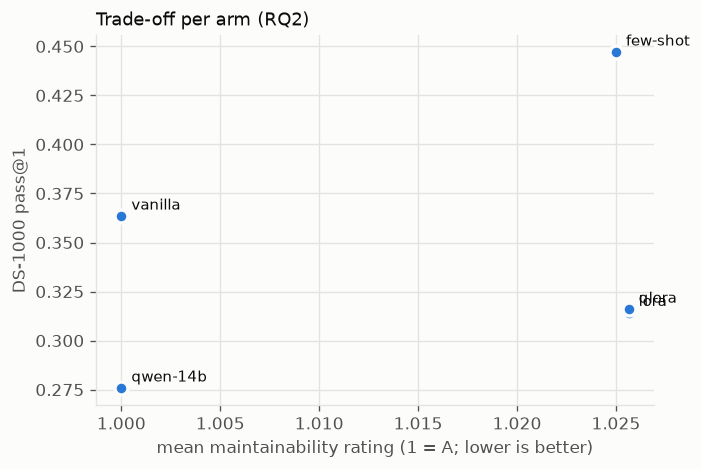

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(tradeoff["mean_maintainability"], tradeoff["pass@1"], s=60, color=BAR, edgecolor=SURFACE, linewidth=2, zorder=3)
for arm, row in tradeoff.iterrows():
    ax.annotate(arm, (row["mean_maintainability"], row["pass@1"]), xytext=(6, 4), textcoords="offset points",
                fontsize=9, color=INK)
ax.set_xlabel("mean maintainability rating (1 = A; lower is better)")
ax.set_ylabel("DS-1000 pass@1")
fig.savefig("bab4-tradeoff.pdf", bbox_inches="tight")   # Fig. in Bab IV; no title, caption only
plt.show()

## 6. Iterative refinement (RQ4)

Two loops per method (LoRA, QLoRA; median seed; the same 200 DS-1000 problems; at most 3 iterations; greedy):
**execution** = feedback is the execution error (`refinement-<method>`), **execution + SonarQube** = the error plus the
SonarQube issues of the failing answer (`refinement-sonar-<method>`, exploratory part of RQ4). A problem leaves a loop once
its tests pass.

Per loop: solved by iteration *i* (cumulative); Cochran's Q over iterations, then McNemar between consecutive iterations
with Holm. **Saturation** = the first iteration whose gain over the previous one is not significant after Holm **and**
whose bootstrap 95% CI includes zero.

In [19]:
LOOPS = {"execution": "refinement", "execution + SonarQube": "refinement-sonar"}


def refinement(prefix, method):
    summary_path = next(f for f in sorted(files) if f.startswith(f"{prefix}-{method}/") and f.endswith("summary.json"))
    summary = json.load(open(get(summary_path)))
    rows = pd.read_json(get(summary_path.replace("summary.json", "refinement_results.jsonl")), lines=True)
    first_pass = rows[rows["passed"]].groupby("problem_id")["iteration"].min()
    iterations = range(summary["max_iterations"] + 1)
    solved = pd.DataFrame({i: [float(first_pass.get(pid, np.inf) <= i) for pid in summary["problem_ids"]] for i in iterations},
                          index=summary["problem_ids"])
    q = cochrans_q(solved.to_numpy())
    print(f"\n=== {prefix}-{method} (seed {summary['seed']}, {len(solved)} problems) | "
          f"solved rate by iteration {[round(x, 4) for x in solved.mean()]} | Cochran's Q={q.statistic:.3f} p={q.pvalue:.4g}")
    steps = []
    for i in list(iterations)[1:]:
        gained = int(((solved[i] == 1) & (solved[i - 1] == 0)).sum())
        lost = int(((solved[i] == 0) & (solved[i - 1] == 1)).sum())
        both = int(((solved[i] == 1) & (solved[i - 1] == 1)).sum())
        p = mcnemar([[both, gained], [lost, len(solved) - both - gained - lost]], exact=True).pvalue
        low, high = bootstrap_ci(solved[i] - solved[i - 1])
        steps.append({"step": f"{i - 1}→{i}", "gain": (solved[i] - solved[i - 1]).mean(), "newly_solved": gained,
                      "ci95_low": low, "ci95_high": high, "p": p})
    steps = pd.DataFrame(steps)
    steps["p_holm"] = holm(steps["p"])
    steps["saturated"] = (steps["p_holm"] >= ALPHA) & (steps["ci95_low"] <= 0) & (steps["ci95_high"] >= 0)
    display(steps.round(4))
    first = steps[steps["saturated"]]
    saturation = int(first.iloc[0]["step"].split("→")[1]) if len(first) else None
    print("saturation point:", f"iteration {saturation}" if saturation is not None else "not reached within the loop")
    return {"rates": solved.mean().tolist(), "saturation": saturation, "solved": solved,
            "path": summary_path.rsplit("/", 1)[0]}


refinement_results = {(loop, method): refinement(prefix, method)
                      for method in ("lora", "qlora") for loop, prefix in LOOPS.items()}


=== refinement-lora (seed 42, 200 problems) | solved rate by iteration [0.415, 0.445, 0.45, 0.455] | Cochran's Q=18.600 p=0.0003307


,step,gain,newly_solved,ci95_low,ci95_high,p,p_holm,saturated
0,0→1,0.030,6,0.01,0.055,0.0312,0.0938,False
1,1→2,0.005,1,0.00,0.015,1.0000,1.0000,True
2,2→3,0.005,1,0.00,0.015,1.0000,1.0000,True


saturation point: iteration 2

=== refinement-sonar-lora (seed 42, 200 problems) | solved rate by iteration [0.425, 0.465, 0.465, 0.465] | Cochran's Q=24.000 p=2.498e-05


,step,gain,newly_solved,ci95_low,ci95_high,p,p_holm,saturated
0,0→1,0.04,8,0.015,0.07,0.0078,0.0234,False
1,1→2,0.00,0,0.000,0.00,1.0000,1.0000,True
2,2→3,0.00,0,0.000,0.00,1.0000,1.0000,True


saturation point: iteration 2

=== refinement-qlora (seed 42, 200 problems) | solved rate by iteration [0.415, 0.445, 0.46, 0.465] | Cochran's Q=22.091 p=6.245e-05


,step,gain,newly_solved,ci95_low,ci95_high,p,p_holm,saturated
0,0→1,0.030,6,0.01,0.055,0.0312,0.0938,False
1,1→2,0.015,3,0.00,0.035,0.2500,0.5000,True
2,2→3,0.005,1,0.00,0.015,1.0000,1.0000,True


saturation point: iteration 2

=== refinement-sonar-qlora (seed 42, 200 problems) | solved rate by iteration [0.405, 0.44, 0.45, 0.45] | Cochran's Q=22.655 p=4.765e-05


,step,gain,newly_solved,ci95_low,ci95_high,p,p_holm,saturated
0,0→1,0.035,7,0.01,0.060,0.0156,0.0469,False
1,1→2,0.010,2,0.00,0.025,0.5000,1.0000,True
2,2→3,0.000,0,0.00,0.000,1.0000,1.0000,True


saturation point: iteration 2


### 6.1 Execution vs execution + SonarQube feedback

Same problems, per method. Generation is not bit-identical between the two runs, so iteration 0 differs slightly; the
loops are therefore compared on the **gain from each loop's own iteration 0** (problem newly solved by the loop = 1):
exact McNemar on the paired gain indicators, paired bootstrap 95% CI of the difference, Holm over the two methods.

In [20]:
rows = []
for method in ("lora", "qlora"):
    a = refinement_results[("execution", method)]["solved"]
    b = refinement_results[("execution + SonarQube", method)]["solved"]
    last = a.columns[-1]
    gain_a = ((a[last] == 1) & (a[0] == 0)).astype(int)
    gain_b = ((b[last] == 1) & (b[0] == 0)).astype(int).reindex(gain_a.index)
    only_a, only_b = int(((gain_a == 1) & (gain_b == 0)).sum()), int(((gain_a == 0) & (gain_b == 1)).sum())
    both = int(((gain_a == 1) & (gain_b == 1)).sum())
    p = mcnemar([[both, only_a], [only_b, len(gain_a) - both - only_a - only_b]], exact=True).pvalue
    low, high = bootstrap_ci(gain_b - gain_a)
    rows.append({"method": method, "iteration0_execution": a[0].mean(), "iteration0_sonar": b[0].mean(),
                 "gain_execution": gain_a.mean(), "gain_sonar": gain_b.mean(), "diff (sonar − execution)": (gain_b - gain_a).mean(),
                 "ci95_low": low, "ci95_high": high, "execution_only": only_a, "sonar_only": only_b, "p": p})
loop_comparison = pd.DataFrame(rows).set_index("method")
loop_comparison["p_holm"] = holm(loop_comparison["p"])
loop_comparison["significant"] = loop_comparison["p_holm"] < ALPHA
loop_comparison.round(4)

,iteration0_execution,iteration0_sonar,gain_execution,gain_sonar,diff (sonar − execution),ci95_low,ci95_high,execution_only,sonar_only,p,p_holm,significant
method,,,,,,,,,,,,
lora,0.415,0.425,0.04,0.040,0.000,-0.025,0.025,3,3,1.0,1.0,False
qlora,0.415,0.405,0.05,0.045,-0.005,-0.015,0.000,1,0,1.0,1.0,False


### 6.2 Structural quality of the final answers

`refinement_ratings.csv` (from `rating/rate_outputs.ipynb`): the final answer per problem of each loop, rated with the
same local SonarQube service. Wilcoxon signed-rank on the problems analysed in both loops (difference = SonarQube loop −
execution loop, so negative = the SonarQube loop is better), Holm within each method; sensitivity on density per
100 `ncloc`.

In [21]:
def load_refinement_ratings(path):
    df = pd.read_csv(get(f"{path}/refinement_ratings.csv")).set_index("problem_id")
    ncloc = pd.to_numeric(df["ncloc"], errors="coerce")
    analysed = ncloc > 0                                   # SonarQube N/A without ncloc
    out = pd.DataFrame(index=df.index)
    out["ncloc"] = ncloc.where(analysed)
    out["maintainability"] = df["maintainability_rating"].map(GRADE).where(analysed)
    for metric in ("code_smells", "complexity", "cognitive_complexity", "bugs"):
        out[metric] = pd.to_numeric(df[metric], errors="coerce").where(analysed)
    out["code_smells_per_100_ncloc"] = 100 * out["code_smells"] / out["ncloc"]
    return out


REFINEMENT_METRICS = ["maintainability", "code_smells", "complexity", "cognitive_complexity", "bugs",
                      "code_smells_per_100_ncloc"]
refinement_structural = {key: load_refinement_ratings(result["path"]) for key, result in refinement_results.items()}

display(pd.DataFrame({f"{loop} | {method}": {"analysed": int(df["ncloc"].notna().sum()), "median_ncloc": df["ncloc"].median(),
                                              **{f"mean_{m}": df[m].mean() for m in REFINEMENT_METRICS}}
                      for (loop, method), df in refinement_structural.items()}).T.round(3))

for method in ("lora", "qlora"):
    print(f"\n=== {method}: execution + SonarQube − execution")
    tests = []
    for metric in REFINEMENT_METRICS:
        table = pd.DataFrame({"sonar": refinement_structural[("execution + SonarQube", method)][metric],
                              "execution": refinement_structural[("execution", method)][metric]})
        if table.dropna().nunique().max() <= 1:
            print(f"{metric}: all values equal, nothing to test")
            continue
        tests.append(wilcoxon_family(table, [("sonar", "execution")]).assign(metric=metric))
    if tests:
        result = pd.concat(tests, ignore_index=True)
        result["p_holm"] = holm(result["p"])                  # Holm over the metrics of this method
        result["significant"] = result["p_holm"] < ALPHA
        display(result.set_index("metric").round(4))

,analysed,median_ncloc,mean_maintainability,mean_code_smells,mean_complexity,mean_cognitive_complexity,mean_bugs,mean_code_smells_per_100_ncloc
execution | lora,197.0,1.0,1.061,0.071,0.183,0.096,0.091,3.130
execution + SonarQube | lora,196.0,1.0,1.031,0.036,0.194,0.087,0.046,1.658
execution | qlora,198.0,1.0,1.051,0.056,0.162,0.076,0.061,2.609
execution + SonarQube | qlora,198.0,1.0,1.040,0.045,0.177,0.076,0.040,2.146



=== lora: execution + SonarQube − execution


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
metric,,,,,,,,
maintainability,sonar − execution,196,0.0,-0.0306,0.1562,-0.7619,0.6250,False
code_smells,sonar − execution,196,0.0,-0.0357,0.1797,-0.6111,0.6250,False
complexity,sonar − execution,196,0.0,0.0102,0.6250,0.5000,1.0000,False
cognitive_complexity,sonar − execution,196,0.0,-0.0102,0.5000,-1.0000,1.0000,False
bugs,sonar − execution,196,0.0,-0.0459,0.0039,-1.0000,0.0234,True
code_smells_per_100_ncloc,sonar − execution,196,0.0,-1.4881,0.0859,-0.6944,0.4297,False



=== qlora: execution + SonarQube − execution


,comparison,n,median_diff,mean_diff,p,rank_biserial,p_holm,significant
metric,,,,,,,,
maintainability,sonar − execution,198,0.0,-0.0101,0.5312,-0.2857,1.0,False
code_smells,sonar − execution,198,0.0,-0.0101,0.8438,-0.1111,1.0,False
complexity,sonar − execution,198,0.0,0.0152,0.5000,0.6000,1.0,False
cognitive_complexity,sonar − execution,198,0.0,0.0000,1.0000,0.0000,1.0,False
bugs,sonar − execution,198,0.0,-0.0202,0.2188,-0.6667,1.0,False
code_smells_per_100_ncloc,sonar − execution,198,0.0,-0.4630,0.8594,-0.0833,1.0,False


#### Figure: refinement curves

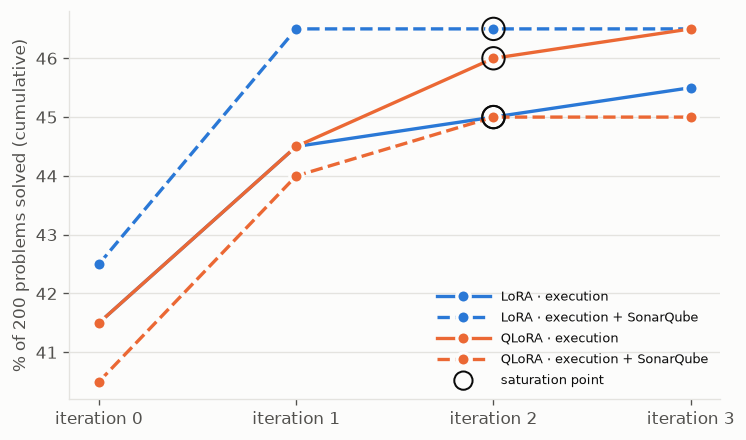

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.2))
DASH = {"execution": "-", "execution + SonarQube": "--"}
for (loop, method), result in refinement_results.items():
    rates = [100 * r for r in result["rates"]]
    its = range(len(rates))
    ax.plot(its, rates, color=LINE[method], linestyle=DASH[loop], linewidth=2, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=f"{ {'lora': 'LoRA', 'qlora': 'QLoRA'}[method]} · {loop}")
    if result["saturation"] is not None:
        s = result["saturation"]
        ax.scatter(s, rates[s], s=180, facecolors="none", edgecolors=INK, linewidth=1.2, zorder=4)
ax.scatter([], [], s=120, facecolors="none", edgecolors=INK, linewidth=1.2, label="saturation point")
ax.set_xticks(range(len(rates)), [f"iteration {i}" for i in range(len(rates))])
ax.set_ylabel("% of 200 problems solved (cumulative)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right", handlelength=4)
fig.savefig("bab4-refinement.pdf", bbox_inches="tight")   # Fig. in Bab IV and the IEEE paper; no title, caption only
plt.show()

## 7. LoRA hyperparameter sensitivity (seed 42)

One changed hyperparameter per adapter, seed 42, compared with the main LoRA run with the same seed (`lora/seed-42`,
r 8, α 16, LR 2e-4, linear scheduler): `cosine` (cosine scheduler + 3% warmup), `r32` (rank 32, α 64), `lr1e-4`
(learning rate 1e-4). Runs `hp-lora-<config>/seed-42`; configs not on the Hub yet are left out. Difference =
config − baseline. The seed range of the main LoRA runs (42/43/44) is the reference for "no real change".

In [23]:
HP_REPO = "dimsmauls/qwen2.5-coder-7b-code4ml-hparam"
HP_RUNS = {"baseline": "lora/seed-42"}
HP_RUNS.update({c: f"hp-lora-{c}/seed-42" for c in ("cosine", "r32", "lr1e-4") if f"hp-lora-{c}/seed-42/summary.json" in files})
HP_PAIRS = [(c, "baseline") for c in HP_RUNS if c != "baseline"]
print("evaluated sensitivity runs:", [HP_RUNS[c] for c, _ in HP_PAIRS] or "none yet")


def hp_metrics(config):
    if config == "baseline":
        return json.load(open(hf_hub_download("dimsmauls/qwen2.5-coder-7b-code4ml-lora", "seed-42/metrics.json")))
    return json.load(open(hf_hub_download(HP_REPO, f"lora-{config}/seed-42/metrics.json")))


# Training: validation loss, epochs, minutes, peak VRAM
pd.DataFrame({c: hp_metrics(c) for c in HP_RUNS}).T[["best_eval_loss", "epochs_run", "train_minutes", "peak_vram_gb", "gpu"]]

evaluated sensitivity runs: ['hp-lora-cosine/seed-42', 'hp-lora-r32/seed-42', 'hp-lora-lr1e-4/seed-42']


,best_eval_loss,epochs_run,train_minutes,peak_vram_gb,gpu
baseline,1.083903,3.0,12.4,28.72,NVIDIA A100-SXM4-80GB
cosine,1.081123,3.0,11.9,28.72,NVIDIA A100-PCIE-40GB
r32,1.062593,3.0,12.2,30.32,NVIDIA A100-PCIE-40GB
lr1e-4,1.101089,3.0,11.9,30.75,NVIDIA A100-PCIE-40GB


### 7.1 Functional correctness (DS-1000, 997 problems)

Exact McNemar vs baseline on the binary pass (sample 0 / any of 10), paired bootstrap 95% CI, Holm over the configs.
Positive difference = the config is better.

In [24]:
hp_summaries = pd.DataFrame({c: json.load(open(get(f"{run}/summary.json")))["ds1000"] for c, run in HP_RUNS.items()}).T
seed_range = pd.DataFrame([summaries[run]["ds1000"] for run in RUNS["lora"]])[["pass@1", "pass@10"]].agg(["min", "max"])
seed_range.index = ["main LoRA seeds min", "main LoRA seeds max"]
display(pd.concat([hp_summaries, seed_range])[["pass@1", "pass@10"]].astype(float).round(4))

hp_binary = {c: ds1000_binary(run) for c, run in HP_RUNS.items()}
for k in ("pass1", "pass10"):
    print(f"\n=== {k}: config − baseline")
    display(mcnemar_family(pd.DataFrame({c: df[k] for c, df in hp_binary.items()}), HP_PAIRS).round(4))

,pass@1,pass@10
baseline,0.3168,0.6179
cosine,0.3086,0.5968
r32,0.3247,0.6108
lr1e-4,0.3223,0.6399
main LoRA seeds min,0.3086,0.6058
main LoRA seeds max,0.3175,0.6179



=== pass1: config − baseline


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,cosine − baseline,997,0.3119,0.3149,-0.0030,-0.0311,0.0241,103,106,0.8900,0.8900,False
1,r32 − baseline,997,0.3300,0.3149,0.0150,-0.0140,0.0431,112,97,0.3329,0.6657,False
2,lr1e-4 − baseline,997,0.3390,0.3149,0.0241,-0.0050,0.0532,122,98,0.1208,0.3624,False



=== pass10: config − baseline


,comparison,n,rate_a,rate_b,diff,ci95_low,ci95_high,a_only,b_only,p,p_holm,significant
0,cosine − baseline,997,0.5968,0.6179,-0.0211,-0.0451,0.0020,61,82,0.0941,0.2582,False
1,r32 − baseline,997,0.6108,0.6179,-0.0070,-0.0311,0.0171,70,77,0.6208,0.6208,False
2,lr1e-4 − baseline,997,0.6399,0.6179,0.0221,-0.0030,0.0461,86,64,0.0861,0.2582,False


### 7.2 Structural quality (Code4ML test, 304 instructions)

Needs `code4ml_ratings.csv` of each `hp-lora-*` run (`rating/rate_outputs.ipynb`). Wilcoxon signed-rank vs baseline per
metric, Holm over the configs; negative difference = the config is better.

In [25]:
ratings.update({run: load_ratings(run) for run in HP_RUNS.values()
                if run not in ratings and f"{run}/code4ml_ratings.csv" in files})
hp_rated = {c: by_instruction(ratings[run]) for c, run in HP_RUNS.items() if run in ratings}
print("not rated yet:", [run for c, run in HP_RUNS.items() if c not in hp_rated] or "none")
display(pd.DataFrame({c: describe(df, [HP_RUNS[c]]) for c, df in hp_rated.items()}).T.round(3))

hp_pairs = [(c, b) for c, b in HP_PAIRS if c in hp_rated]
if hp_pairs:
    hp_structural = pd.concat([wilcoxon_family(pd.DataFrame({c: df[m] for c, df in hp_rated.items()}), hp_pairs).assign(metric=m)
                               for m in METRICS], ignore_index=True)
    display(hp_structural.set_index(["metric", "comparison"]).round(4))
else:
    print("no sensitivity run is rated yet")

not rated yet: none


,ast_valid_rate,sonar_rated,mlscent_rated,median_ncloc,maintainability_A_%,mean_maintainability,mean_code_smells,mean_complexity,mean_cognitive_complexity,mean_bugs,mean_mlscent_ml_rating,mean_code_smells_per_100_ncloc,mean_ml_findings_per_100_ncloc
baseline,0.990,40.0,10.0,2.0,97.5,1.025,0.075,0.025,0.000,0.000,1.200,1.964,10.714
cosine,1.000,40.0,10.0,3.0,97.5,1.025,0.075,0.075,0.075,0.000,1.200,1.964,10.714
r32,1.000,40.0,10.0,2.0,95.0,1.050,0.125,0.000,0.000,0.050,1.300,2.859,13.769
lr1e-4,0.947,40.0,8.0,2.0,97.5,1.025,0.100,0.200,0.200,0.025,1.375,2.312,13.750


n  median_diff  mean_diff      p  rank_biserial  p_holm  significant
metric                    comparison                                                                              
maintainability           cosine − baseline  40          0.0     0.0000  1.000         0.0000   1.000        False
                          r32 − baseline     40          0.0     0.0250  1.000         1.0000   1.000        False
                          lr1e-4 − baseline  40          0.0     0.0000  1.000         0.0000   1.000        False
code_smells               cosine − baseline  40          0.0     0.0000  1.000         0.0000   1.000        False
                          r32 − baseline     40          0.0     0.0500  0.500         1.0000   1.000        False
                          lr1e-4 − baseline  40          0.0     0.0250  1.000         0.3333   1.000        False
complexity                cosine − baseline  40          0.0     0.0500  0.500         1.0000   1.000        False
                          r32 − baseline     40          0.0    -0.0250  1.000        -1.0000   1.000        False
                          lr1e-4 − baseline  40          0.0     0.1750  0.250         0.7333   0.750        False
cognitive_complexity      cosine − baseline  40          0.0     0.0750  0.250         1.0000   0.500        False
                          r32 − baseline     40          0.0     0.0000  1.000         0.0000   1.000        False
                          lr1e-4 − baseline  40          0.0     0.2000  0.125         1.0000   0.375        False
bugs                      cosine − baseline  40          0.0     0.0000  1.000         0.0000   1.000        False
                          r32 − baseline     40          0.0     0.0500  0.500         1.0000   1.000        False
                          lr1e-4 − baseline  40          0.0     0.0250  1.000         1.0000   1.000        False
mlscent_ml_rating         cosine − baseline  10          0.0     0.0000  1.000         0.0000   1.000        False
                          r32 − baseline     10          0.0     0.1000  1.000         1.0000   1.000        False
                          lr1e-4 − baseline   8          0.0     0.1250  1.000         1.0000   1.000        False
code_smells_per_100_ncloc cosine − baseline  40          0.0     0.0000  1.000         0.0000   1.000        False
                          r32 − baseline     40          0.0     0.8947  0.250         1.0000   0.750        False
                          lr1e-4 − baseline  40          0.0     0.3482  0.500         0.6667   1.000        False
ml_findings_per_100_ncloc cosine − baseline  10          0.0     0.0000  1.000         0.0000   1.000        False
                          r32 − baseline     10          0.0     3.0549  0.500         1.0000   1.000        False
                          lr1e-4 − baseline   8          0.0     0.3571  1.000         0.3333   1.000        False

#### Figures: all arms with the sensitivity configs

Main arms (blue; LoRA / QLoRA = mean of the 3 seeds) next to `lora seed-42` and the three configs trained from it
(orange). The structural chart appears once the `hp-lora-*` runs are rated.

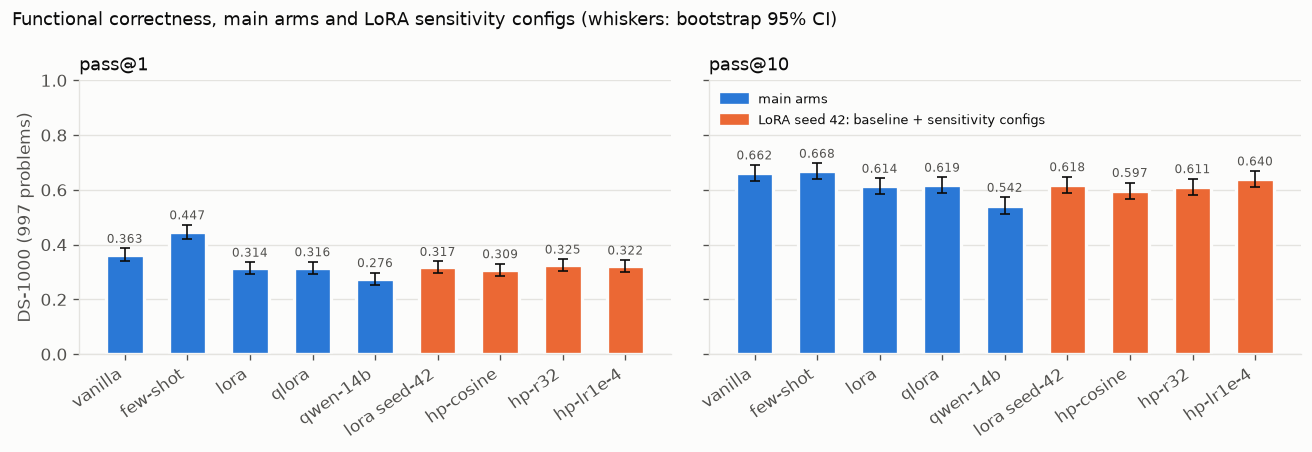

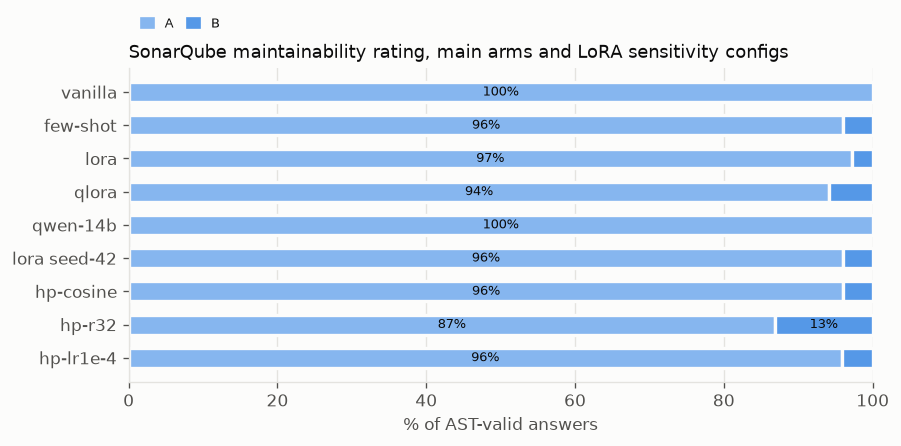

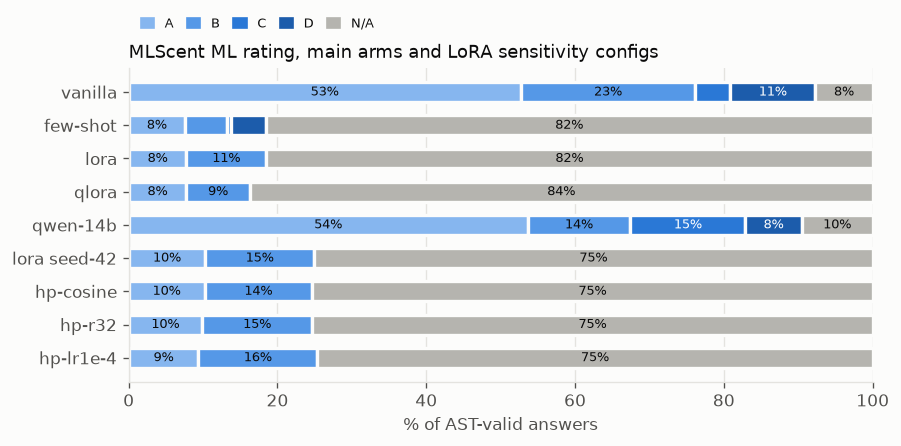

In [26]:
HP_COLOR = "#eb6834"
hp_labels = {c: "lora seed-42" if c == "baseline" else f"hp-{c}" for c in HP_RUNS}
per_problem.update({run: pd.DataFrame(json.load(open(get(f"{run}/ds1000_per_problem.json")))).T.astype(float)
                    for run in HP_RUNS.values() if run not in per_problem})
groups = [(arm, RUNS[arm], BAR) for arm in ARM_ORDER] + [(hp_labels[c], [run], HP_COLOR) for c, run in HP_RUNS.items()]
legend = ([plt.Rectangle((0, 0), 1, 1, color=c) for c in (BAR, HP_COLOR)],
          ["main arms", "LoRA seed 42: baseline + sensitivity configs"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, k in zip(axes, ("pass@1", "pass@10")):
    for x, (label, runs, color) in enumerate(groups):
        values = pd.concat([per_problem[r][k] for r in runs], axis=1).mean(axis=1)   # mean of seeds per problem
        value = values.mean()
        low, high = bootstrap_ci(values)
        ax.bar(x, value, width=0.6, color=color, edgecolor=SURFACE, linewidth=2)
        ax.errorbar(x, value, yerr=[[value - low], [high - value]], color=INK, capsize=3, linewidth=1)
        ax.text(x, high + 0.02, f"{value:.3f}", ha="center", fontsize=7, color=INK_2)
    ax.set_xticks(range(len(groups)), [g[0] for g in groups], rotation=35, ha="right")
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.set_title(k, loc="left", fontsize=11)
axes[0].set_ylabel("DS-1000 (997 problems)")
axes[1].legend(*legend, frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Functional correctness, main arms and LoRA sensitivity configs (whiskers: bootstrap 95% CI)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()


def shares_with_hp(column):
    """grade_shares of the main arms plus one row per rated lora seed-42 / sensitivity run."""
    shares = grade_shares(column)
    for c, run in HP_RUNS.items():
        if run not in ratings:
            continue
        values = ratings[run].loc[lambda df: df["ast_valid"], column]
        shares.loc[hp_labels[c]] = [100 * (values == g).mean() for g in range(1, 6)] + [100 * values.isna().mean()]
    return shares


if hp_pairs:
    stacked_bars(shares_with_hp("maintainability"), "SonarQube maintainability rating, main arms and LoRA sensitivity configs")
    stacked_bars(shares_with_hp("mlscent_ml_rating"), "MLScent ML rating, main arms and LoRA sensitivity configs")
else:
    print("structural chart skipped: no sensitivity run is rated yet")